# 경로 설정

In [1]:
BASE_DIR = "lerobot_project"
VENV_NAME = "lerobot_env"
PYTHON_VERSION = "3.12"
REPO_NAME = "lerobot-ac-mlp"

import os, sys, subprocess
os.environ['MPLBACKEND'] = 'Agg'
home_dir = os.path.expanduser('~')
base_path = os.path.join(home_dir, BASE_DIR)
venv_path = os.path.join(base_path, VENV_NAME)
site_packages = os.path.join(venv_path, 'lib', f'python{PYTHON_VERSION}', 'site-packages')
if site_packages not in sys.path: sys.path.insert(0, site_packages)
python_exec = os.path.join(venv_path, 'bin', 'python')
pip_exec = os.path.join(venv_path, 'bin', 'pip')
project_dir = os.path.join(base_path, REPO_NAME)
src_path = os.path.join(project_dir, 'src')
if src_path not in sys.path: sys.path.insert(0, src_path)

# --- 렌더링 환경 설정 (osmesa) ---
conda_lib = os.path.join(home_dir, 'miniconda3', 'lib')
lib_dirs = {conda_lib}
r = subprocess.run(['bash', '-c', f'find {home_dir}/miniconda3 -name "libOSMesa*" -o -name "libEGL*" 2>/dev/null'],
                    capture_output=True, text=True, timeout=15)
for line in r.stdout.strip().split('\n'):
    if line.strip(): lib_dirs.add(os.path.dirname(line.strip()))
ld_path = ':'.join(lib_dirs) + ':' + os.environ.get('LD_LIBRARY_PATH', '')
os.environ['LD_LIBRARY_PATH'] = ld_path
os.environ['MUJOCO_GL'] = 'osmesa'

%cd {project_dir}
print(f"Project: {project_dir}")
print(f"Rendering: {os.environ['MUJOCO_GL']}")
!git branch --show-current

/home1/eunji24/lerobot_project/lerobot-ac-mlp
Project: /home1/eunji24/lerobot_project/lerobot-ac-mlp
Rendering: osmesa
ecd-eunji


In [2]:
import os
from pathlib import Path

print("cwd:", os.getcwd())

for p in Path(".").glob("**/episode_*.pt"):
    print(p)

cwd: /home1/eunji24/lerobot_project/lerobot-ac-mlp
src/outputs/eval/insertion_act_ckpt_020000/videos/action_logs/episode_0005.pt
src/outputs/eval/insertion_act_ckpt_020000/videos/action_logs/episode_0034.pt
src/outputs/eval/insertion_act_ckpt_020000/videos/action_logs/episode_0015.pt
src/outputs/eval/insertion_act_ckpt_020000/videos/action_logs/episode_0022.pt
src/outputs/eval/insertion_act_ckpt_020000/videos/action_logs/episode_0036.pt
src/outputs/eval/insertion_act_ckpt_020000/videos/action_logs/episode_0048.pt
src/outputs/eval/insertion_act_ckpt_020000/videos/action_logs/episode_0010.pt
src/outputs/eval/insertion_act_ckpt_020000/videos/action_logs/episode_0027.pt
src/outputs/eval/insertion_act_ckpt_020000/videos/action_logs/episode_0028.pt
src/outputs/eval/insertion_act_ckpt_020000/videos/action_logs/episode_0042.pt
src/outputs/eval/insertion_act_ckpt_020000/videos/action_logs/episode_0031.pt
src/outputs/eval/insertion_act_ckpt_020000/videos/action_logs/episode_0024.pt
src/outputs/e

# ACT

### baseline과 temporal ensemble
boundary jump & jerk

In [1]:
import os

os.environ["MUJOCO_GL"] = "egl"
os.environ["PYOPENGL_PLATFORM"] = "egl"

In [2]:
#!/usr/bin/env python
import sys
sys.path.insert(0, "/home1/eunji24/lerobot_project/lerobot-ac-mlp/src")

import time
from pathlib import Path
from collections import defaultdict

import torch
import torch.nn.functional as F
import numpy as np
from tqdm import tqdm

from lerobot.policies.act.modeling_act import ACTPolicy
from lerobot.policies.acm.modeling_acm import ACMPolicy
from lerobot.policies.factory import make_pre_post_processors
from lerobot.envs.factory import make_env, make_env_pre_post_processors
from lerobot.envs.utils import preprocess_observation, add_envs_task
from lerobot.envs.configs import AlohaEnv


ACT_DIR = Path("/home1/eunji24/lerobot_project/outputs/train/act_network_baseline_100k/checkpoints/last/pretrained_model")
ACM_DIR = Path("/home1/eunji24/lerobot_project/lerobot-ac-mlp/outputs/train/acm_transfer_cube_test_100k/checkpoints/060000/pretrained_model")

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
TASK = "AlohaTransferCube-v0"

N_ENVS = 1
N_STEPS = 400
SEED = 0


def make_policy(kind: str):
    if kind == "act":
        print(f"[LOAD] ACT from {ACT_DIR}")
        policy = ACTPolicy.from_pretrained(str(ACT_DIR)).to(DEVICE)
    elif kind == "acm":
        print(f"[LOAD] ACM from {ACM_DIR}")
        policy = ACMPolicy.from_pretrained(str(ACM_DIR)).to(DEVICE)
    else:
        raise ValueError(kind)

    policy.eval()
    policy.reset()
    return policy


def make_eval_env(policy_config):
    env_cfg = AlohaEnv(task=TASK)
    env_obj = make_env(env_cfg, n_envs=N_ENVS, use_async_envs=False)

    while isinstance(env_obj, dict):
        print("make_env returned dict keys:", env_obj.keys())
        env_obj = list(env_obj.values())[0]

    env_preprocessor, env_postprocessor = make_env_pre_post_processors(
        env_cfg=env_cfg,
        policy_cfg=policy_config,
    )
    return env_obj, env_preprocessor, env_postprocessor, env_cfg


@torch.no_grad()
def collect_chunks(policy, kind: str):
    preprocessor, postprocessor = make_pre_post_processors(
        policy_cfg=policy.config,
        pretrained_path=str(ACT_DIR if kind == "act" else ACM_DIR),
        preprocessor_overrides={"device_processor": {"device": str(DEVICE)}},
    )

    env, env_preprocessor, env_postprocessor, env_cfg = make_eval_env(policy.config)

    obs_dict, _ = env.reset(seed=[SEED])
    chunks = []
    executed_actions = []

    max_steps = min(N_STEPS, env.call("_max_episode_steps")[0])
    done = np.array([False])

    print(f"[COLLECT] {kind}, steps={max_steps}")

    for step in tqdm(range(max_steps)):
        obs = preprocess_observation(obs_dict)
        obs = add_envs_task(env, obs)
        obs = env_preprocessor(obs)
        obs = preprocessor(obs)

        # 핵심: 매 step 강제로 action chunk 예측
        chunk = policy.predict_action_chunk(obs)  # [B, L, A]
        chunks.append(chunk[0].detach().cpu())

        # 실제 executed action은 n_action_steps 정책대로 select_action 사용
        action = policy.select_action(obs)
        executed_actions.append(action[0].detach().cpu())

        action_env = postprocessor(action)
        action_env = env_postprocessor({"action": action_env})["action"]
        action_np = action_env.to("cpu").numpy()

        obs_dict, reward, terminated, truncated, info = env.step(action_np)
        done = done | terminated | truncated
        if done.all():
            break

    env.close()

    chunks = torch.stack(chunks, dim=0)              # [T, L, A]
    executed_actions = torch.stack(executed_actions, dim=0)  # [T, A]
    return chunks, executed_actions


def l2_mean(x):
    return torch.norm(x, dim=-1).mean().item()


def l2_max(x):
    return torch.norm(x, dim=-1).max().item()


def analyze_chunks(chunks):
    """
    chunks: [T, L, A]
    """
    T, L, A = chunks.shape

    # 1) timestep 간 overlap consistency
    # chunk_t[1:] 과 chunk_{t+1}[:-1]는 같은 미래 시간대를 예측
    overlap = chunks[:-1, 1:, :] - chunks[1:, :-1, :]  # [T-1, L-1, A]
    overlap_l2 = torch.norm(overlap, dim=-1)            # [T-1, L-1]

    # 2) chunk 내부 smoothness
    vel = chunks[:, 1:, :] - chunks[:, :-1, :]          # [T, L-1, A]
    acc = vel[:, 1:, :] - vel[:, :-1, :]                # [T, L-2, A]
    jerk = acc[:, 1:, :] - acc[:, :-1, :]               # [T, L-3, A]

    return {
        "chunk_overlap_mean": overlap_l2.mean().item(),
        "chunk_overlap_max": overlap_l2.max().item(),
        "chunk_overlap_first10_mean": overlap_l2[:, :10].mean().item(),
        "chunk_overlap_last10_mean": overlap_l2[:, -10:].mean().item(),

        "chunk_vel_mean": torch.norm(vel, dim=-1).mean().item(),
        "chunk_vel_max": torch.norm(vel, dim=-1).max().item(),

        "chunk_acc_mean": torch.norm(acc, dim=-1).mean().item(),
        "chunk_acc_max": torch.norm(acc, dim=-1).max().item(),

        "chunk_jerk_mean": torch.norm(jerk, dim=-1).mean().item(),
        "chunk_jerk_max": torch.norm(jerk, dim=-1).max().item(),
    }


def analyze_executed(actions):
    """
    actions: [T, A]
    """
    vel = actions[1:] - actions[:-1]
    acc = vel[1:] - vel[:-1]
    jerk = acc[1:] - acc[:-1]

    return {
        "exec_vel_mean": torch.norm(vel, dim=-1).mean().item(),
        "exec_vel_max": torch.norm(vel, dim=-1).max().item(),
        "exec_acc_mean": torch.norm(acc, dim=-1).mean().item(),
        "exec_acc_max": torch.norm(acc, dim=-1).max().item(),
        "exec_jerk_mean": torch.norm(jerk, dim=-1).mean().item(),
        "exec_jerk_max": torch.norm(jerk, dim=-1).max().item(),
    }


def print_table(results):
    keys = list(next(iter(results.values())).keys())

    print("\n" + "=" * 120)
    print("CHUNK / ACTION STABILITY RESULTS")
    print("=" * 120)
    print(f"{'metric':35s} | {'ACT':>12s} | {'ACM':>12s} | {'diff':>12s} | {'ratio':>8s} | {'% increase':>10s}")
    print("-" * 120)

    for k in keys:
        act = results["act"][k]
        acm = results["acm"][k]
        diff = acm - act
        ratio = acm / act if abs(act) > 1e-12 else float("nan")
        pct = (ratio - 1.0) * 100.0 if abs(act) > 1e-12 else float("nan")

        print(
            f"{k:35s} | "
            f"{act:12.6f} | "
            f"{acm:12.6f} | "
            f"{diff:12.6f} | "
            f"{ratio:8.3f} | "
            f"{pct:9.1f}%"
        )

    print("=" * 120)


def main():
    all_results = {}

    for kind in ["act", "acm"]:
        policy = make_policy(kind)
        chunks, executed = collect_chunks(policy, kind)

        print(f"[SHAPE] {kind} chunks:", tuple(chunks.shape))
        print(f"[SHAPE] {kind} executed:", tuple(executed.shape))

        chunk_stats = analyze_chunks(chunks)
        exec_stats = analyze_executed(executed)

        all_results[kind] = {**chunk_stats, **exec_stats}

        out_path = Path(f"/home1/eunji24/lerobot_project/outputs/chunk_stability_{kind}.pt")
        torch.save(
            {
                "chunks": chunks,
                "executed_actions": executed,
                "stats": all_results[kind],
            },
            out_path,
        )
        print(f"[SAVE] {out_path}")

    print_table(all_results)


if __name__ == "__main__":
    main()

/home1/eunji24/miniconda3/envs/lerobot_mamba/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


[LOAD] ACT from /home1/eunji24/lerobot_project/outputs/train/act_network_baseline_100k/checkpoints/last/pretrained_model
Loading weights from local directory
gym id 'gym_aloha/AlohaTransferCube-v0' not found, attempting to import 'gym_aloha'...


ImportError: Cannot initialize a headless EGL display.

=== baseline vs ensemble ===
baseline mean jerk: 0.03776797279715538
ensemble mean jerk: 0.002516046864911914
baseline mean boundary jump: 0.04204346239566803
ensemble mean boundary jump: 0.029238052666187286


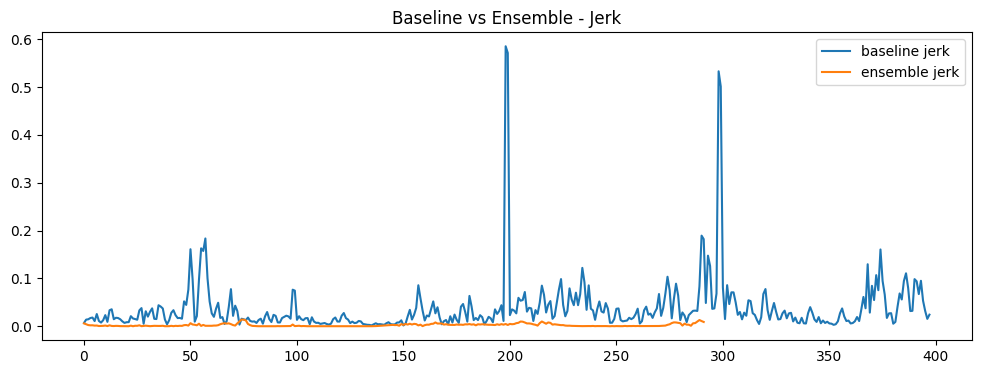

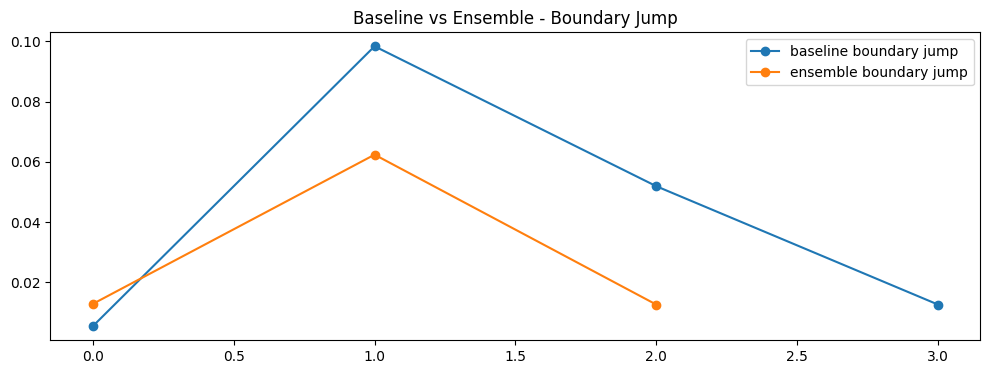

In [4]:
%matplotlib inline
import torch
import matplotlib.pyplot as plt

BASE_PATH = "outputs/eval/act_ens_base/videos/action_logs/episode_0001.pt"
ORIG_PATH = "outputs/eval/act_ens_001/videos/action_logs/episode_0001.pt"

N_ACTION_STEPS = 80

def load_actions(path):
    data = torch.load(path)
    actions = data["actions"].float()
    if actions.ndim == 3 and actions.shape[1] == 1:
        actions = actions.squeeze(1)
    return actions

def jerk_l2(actions):
    jerk = actions[2:] - 2 * actions[1:-1] + actions[:-2]
    return torch.norm(jerk, dim=-1)

def boundary_jump(actions, n_action_steps):
    vals = []
    T = actions.shape[0]
    for b in range(n_action_steps, T, n_action_steps):
        vals.append(torch.norm(actions[b] - actions[b - 1], dim=-1))
    return torch.stack(vals) if vals else None

base = load_actions(BASE_PATH)
orig = load_actions(ORIG_PATH)

base_jerk = jerk_l2(base)
orig_jerk = jerk_l2(orig)

base_jump = boundary_jump(base, N_ACTION_STEPS)
orig_jump = boundary_jump(orig, N_ACTION_STEPS)

print("=== baseline vs ensemble ===")
print("baseline mean jerk:", base_jerk.mean().item())
print("ensemble mean jerk:", orig_jerk.mean().item())

print("baseline mean boundary jump:", base_jump.mean().item() if base_jump is not None else None)
print("ensemble mean boundary jump:", orig_jump.mean().item() if orig_jump is not None else None)

plt.figure(figsize=(12,4))
plt.plot(base_jerk.numpy(), label="baseline jerk")
plt.plot(orig_jerk.numpy(), label="ensemble jerk")
plt.title("Baseline vs Ensemble - Jerk")
plt.legend()
plt.show()

plt.figure(figsize=(12,4))
if base_jump is not None:
    plt.plot(base_jump.numpy(), marker="o", label="baseline boundary jump")
if orig_jump is not None:
    plt.plot(orig_jump.numpy(), marker="o", label="ensemble boundary jump")
plt.title("Baseline vs Ensemble - Boundary Jump")
plt.legend()
plt.show()

### baseline과 chunk ensemble
boundary jump & jerk

In [7]:
%matplotlib inline
import torch
import matplotlib.pyplot as plt

BASE_PATH = "outputs/eval/acm_ens_test_100k_50/orign_ens_coeff_001_action_logs/episode_0001.pt"
ORIG_PATH = "outputs/eval/act_ens_001/videos/action_logs/episode_0001.pt"

N_ACTION_STEPS = 80

def load_actions(path):
    data = torch.load(path)
    actions = data["actions"].float()
    if actions.ndim == 3 and actions.shape[1] == 1:
        actions = actions.squeeze(1)
    return actions

def jerk_l2(actions):
    jerk = actions[2:] - 2 * actions[1:-1] + actions[:-2]
    return torch.norm(jerk, dim=-1)

def boundary_jump(actions, n_action_steps):
    vals = []
    T = actions.shape[0]
    for b in range(n_action_steps, T, n_action_steps):
        vals.append(torch.norm(actions[b] - actions[b - 1], dim=-1))
    return torch.stack(vals) if vals else None

base = load_actions(BASE_PATH)
orig = load_actions(ORIG_PATH)

base_jerk = jerk_l2(base)
orig_jerk = jerk_l2(orig)

base_jump = boundary_jump(base, N_ACTION_STEPS)
orig_jump = boundary_jump(orig, N_ACTION_STEPS)

print("=== baseline vs ensemble ===")
print("baseline mean jerk:", base_jerk.mean().item())
print("ensemble mean jerk:", orig_jerk.mean().item())

print("baseline mean boundary jump:", base_jump.mean().item() if base_jump is not None else None)
print("ensemble mean boundary jump:", orig_jump.mean().item() if orig_jump is not None else None)

plt.figure(figsize=(12,4))
plt.plot(base_jerk.numpy(), label="baseline jerk")
plt.plot(orig_jerk.numpy(), label="ensemble jerk")
plt.title("Baseline vs Ensemble - Jerk")
plt.legend()
plt.show()

plt.figure(figsize=(12,4))
if base_jump is not None:
    plt.plot(base_jump.numpy(), marker="o", label="baseline boundary jump")
if orig_jump is not None:
    plt.plot(orig_jump.numpy(), marker="o", label="ensemble boundary jump")
plt.title("Baseline vs Ensemble - Boundary Jump")
plt.legend()
plt.show()

FileNotFoundError: [Errno 2] No such file or directory: 'outputs/eval/acm_ens_test_100k_50/orign_ens_coeff_001_action_logs/episode_0001.pt'